# CDS4003 – Data Science Final Project
## Notebook 02 – Stage 4: Exploratory Data Analysis and Feature Engineering

**Prerequisite:** notebook 01 completed (the cleaned dataset and settings are in your Drive folder `Used-Vehicle-Price-Prediction`).
**Outputs:** EDA figures (`outputs/figures/`), `outputs/feature_engineering_table.csv`, and the shared feature code `src/vehicle_features.py`, which notebook 03 and the app use.

### Setup
The next cells load the libraries, connect to your Drive project folder and read the cleaned dataset.

In [ ]:
# ---- Libraries ----
import re
import sys
import json
import shutil
import warnings
from pathlib import Path
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

warnings.simplefilter("ignore", category=FutureWarning)      # hides harmless deprecation notices only
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 220)
pd.set_option("display.max_colwidth", 60)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100

IN_COLAB = "google.colab" in sys.modules

# ---- Project folder in Google Drive (shared by notebooks 01-04) ----
if IN_COLAB:
    from google.colab import drive
    if not Path("/content/drive/MyDrive").exists():
        drive.mount("/content/drive")
    PROJECT_DIR = Path("/content/drive/MyDrive/Used-Vehicle-Price-Prediction")
else:
    PROJECT_DIR = Path("Used-Vehicle-Price-Prediction")

RAW_DIR, PROCESSED_DIR, SAMPLE_DIR = PROJECT_DIR / "data/raw", PROJECT_DIR / "data/processed", PROJECT_DIR / "data/sample"
OUTPUT_DIR, FIG_DIR = PROJECT_DIR / "outputs", PROJECT_DIR / "outputs/figures"
NOTEBOOK_DIR, MODEL_DIR, APP_DIR, SRC_DIR, DOCS_DIR = (PROJECT_DIR / n for n in ["notebooks", "models", "app", "src", "docs"])

settings_path = OUTPUT_DIR / "cleaning_settings.json"
if not settings_path.exists():
    raise FileNotFoundError(f"{settings_path} not found. Run notebook 01 completely first (it saves the cleaned data and settings "
                            f"in {PROJECT_DIR}).")
for folder in [FIG_DIR, MODEL_DIR, APP_DIR, SRC_DIR, DOCS_DIR, NOTEBOOK_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

# ---- Settings decided in notebook 01 (the same rules are used everywhere) ----
cleaning_settings = json.loads(settings_path.read_text(encoding="utf-8"))
DATA_COLLECTION_YEAR = cleaning_settings["DATA_COLLECTION_YEAR"]
PRICE_MAX_PLAUSIBLE = cleaning_settings["PRICE_MAX_PLAUSIBLE"]
PRICE_LOW_REVIEW = cleaning_settings["PRICE_LOW_REVIEW"]

def std_name(name):
    """Standard column name: stripped, lowercase, spaces replaced by underscores."""
    return re.sub(r"\s+", "_", str(name).strip().lower())

def load_cleaned(usecols=None):
    """Read the cleaned dataset saved by notebook 01."""
    path = PROCESSED_DIR / "vehicles_cleaned.csv"
    if not path.exists():
        raise FileNotFoundError(f"{path} not found. Run notebook 01 completely first.")
    df = pd.read_csv(path, usecols=usecols, low_memory=False, keep_default_na=False, na_values=[""])
    if "posting_date" in df.columns:
        df["posting_date"] = pd.to_datetime(df["posting_date"], errors="coerce", utc=True)
    return df

def save_fig(name):
    """Save the current figure into outputs/figures (used as report evidence)."""
    FIG_DIR.mkdir(parents=True, exist_ok=True)
    path = FIG_DIR / f"{name}.png"
    plt.savefig(path, dpi=150, bbox_inches="tight")
    return path

print(f"Project folder          : {PROJECT_DIR}")
print(f"Data-collection year    : {DATA_COLLECTION_YEAR}")
print(f"Records after cleaning  : {cleaning_settings['records_cleaned']:,} (from {cleaning_settings['records_raw']:,} raw records)")

Mounted at /content/drive
Project folder          : /content/drive/MyDrive/Used-Vehicle-Price-Prediction
Data-collection year    : 2026
Records after cleaning  : 240,186 (from 295,451 raw records)


In [ ]:
df_cleaned = load_cleaned()
print(f"Cleaned dataset loaded: {df_cleaned.shape}")
display(df_cleaned.head(3))

Cleaned dataset loaded: (240186, 43)


,id,url,region,region_url,price,year,manufacturer,model,condition,cylinders,fuel,odometer,title_status,transmission,vin,drive,type,paint_color,image_url,description,state,lat,long,posting_date,seller_type,title,updated_date,address_street,address_city,address_state,address_postal_code,address_country,image_count,image_urls,delivery_available,odometer_broken,odometer_rolled_over,monthly_payment,other_attributes,flag_price_iqr_outlier,flag_year_iqr_outlier,flag_odometer_iqr_outlier,flag_low_price
0,7994372850,https://sfbay.craigslist.org/ctd/d/sunnyvale-2022-ford-e...,SF bay area,https://sfbay.craigslist.org,27999,2022.0,ford,explorer st,excellent,6 cylinders,gas,99179.0,clean,automatic,1FM5K8GCXNGA77516,4wd,suv,grey,https://images.craigslist.org/00N0N_aBzbdTBI4cO_0eI0b0_6...,⭐ Autorace ⭐ 🏷️ STOCK #: 1726 📞 CALL OR TEXT: (669) 248-...,ca,37.371435,-122.047863,2026-11-03 03:24:16+00:00,dealer,2022 Ford Explorer ST,NaN,975 West El Camino Real,Sunnyvale,CA,94088,US,20,https://images.craigslist.org/00N0N_aBzbdTBI4cO_0eI0b0_6...,0,0,0,NaN,NaN,False,False,False,False
1,7994372787,https://sfbay.craigslist.org/cto/d/mill-valley-69-vw-bug...,SF bay area,https://sfbay.craigslist.org,2200,1969.0,volkswagen,bug,fair,4 cylinders,gas,90000.0,clean,manual,NaN,rwd,other,green,https://images.craigslist.org/00n0n_gNzbApFpKG4_0CI0t2_6...,I am selling a 1969Vw Bug all original. This is a good m...,ca,37.906000,-122.545000,2026-11-03 03:23:52+00:00,owner,69 VW Bug All Original Runs and drives current registration,NaN,NaN,Mill Valley,CA,94942,US,4,https://images.craigslist.org/00n0n_gNzbApFpKG4_0CI0t2_6...,0,0,0,NaN,NaN,False,True,False,False
2,7994372559,https://sfbay.craigslist.org/ctd/d/sunnyvale-2016-land-r...,SF bay area,https://sfbay.craigslist.org,15999,2016.0,rover,sport,excellent,6 cylinders,gas,82896.0,clean,automatic,SALWR2VF6GA636931,4wd,suv,white,https://images.craigslist.org/00Z0Z_3KNlCaCAM2h_0eI0b0_6...,⭐ Autorace ⭐ 🏷️ STOCK #: 1544 📞 CALL OR TEXT: (669) 248-...,ca,37.371435,-122.047863,2026-11-03 03:22:44+00:00,dealer,2016 Land Rover Range Rover Sport 3.0L V6 Supercharged HSE,2026-11-02T19:22:45-0800,975 West El Camino Real,Sunnyvale,CA,94088,US,20,https://images.craigslist.org/00Z0Z_3KNlCaCAM2h_0eI0b0_6...,0,0,0,NaN,NaN,False,False,False,False


---
# STAGE 4 – Exploratory Data Analysis and Feature Engineering

**Input:** `df_cleaned`, the cleaned dataset saved by notebook 01. **Goal:** find the patterns that drive used-vehicle prices, explain them in business terms, and create meaningful features for modelling.

**Rules followed in this stage**
- Every statement about the data is generated from the actual numbers when the cell runs.
- Features use only the listing's *own* attributes and fixed constants. Nothing is computed from the target (`price`) and no dataset-wide statistic is learned, so there is **no data leakage**.
- The `flag_*` columns created in Stage 3 are **not** used as features: the price flags are derived from `price` itself.

## 18. EDA Setup and the Target Variable

**What will happen?** We look at the distribution of `price`, the variable we want to predict.
**Why?** Prices are usually strongly right-skewed (many cheap cars, few very expensive ones). The shape of the target decides how we model it – for example whether a logarithm helps.

,price (US$)
count,240186.0
mean,18473.0
std,20622.0
min,1.0
1%,509.0
25%,6950.0
50%,12999.0
75%,23245.0
99%,89995.0
max,999999.0


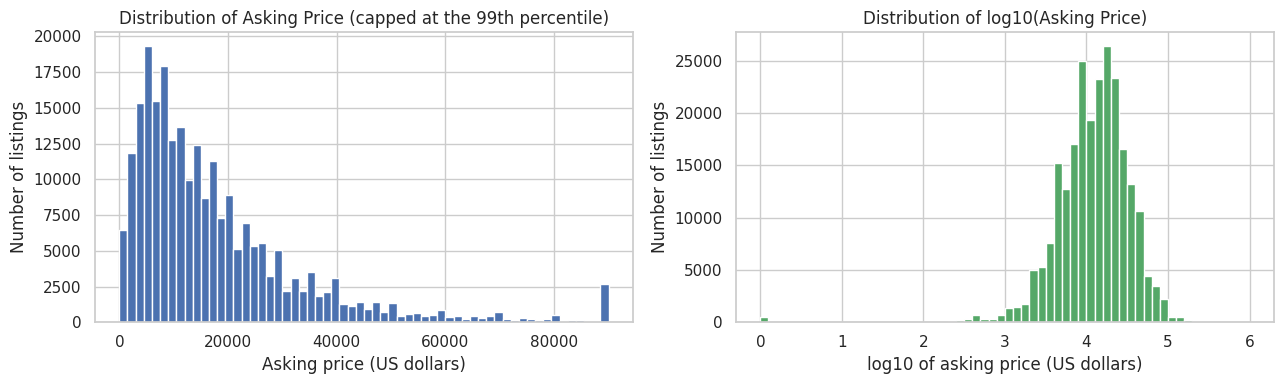

Median asking price : $12,999   |   mean : $18,473
Skewness of price   : 6.75   ->   skewness of log(price): -1.87
Business reading: the mean is above the median because a few expensive vehicles pull it up; a log transformation makes the distribution much more symmetric.


In [ ]:
df_eda = df_cleaned                                   # read-only view used for exploration
eda_sample = df_eda.sample(n=min(60_000, len(df_eda)), random_state=42)   # for slow scatter-type charts only
price_all = df_eda["price"].astype(float)
MIN_GROUP = max(30, int(len(df_eda) * 0.002))         # categories smaller than this are ignored in group comparisons

display(price_all.describe(percentiles=[0.01, 0.25, 0.5, 0.75, 0.99]).round(0).to_frame("price (US$)"))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(price_all.clip(upper=price_all.quantile(0.99)), bins=60, color="#4C72B0")
axes[0].set_title("Distribution of Asking Price (capped at the 99th percentile)")
axes[0].set_xlabel("Asking price (US dollars)")
axes[0].set_ylabel("Number of listings")
axes[1].hist(np.log10(price_all), bins=60, color="#55A868")
axes[1].set_title("Distribution of log10(Asking Price)")
axes[1].set_xlabel("log10 of asking price (US dollars)")
axes[1].set_ylabel("Number of listings")
plt.tight_layout()
save_fig("01_price_distribution")
plt.show()

skew_raw, skew_log = price_all.skew(), np.log1p(price_all).skew()
print(f"Median asking price : ${price_all.median():,.0f}   |   mean : ${price_all.mean():,.0f}")
print(f"Skewness of price   : {skew_raw:.2f}   ->   skewness of log(price): {skew_log:.2f}")
print("Business reading: the mean is above the median because a few expensive vehicles pull it up; "
      "a log transformation makes the distribution much more symmetric." if skew_log < skew_raw else
      "Business reading: the log transformation did not reduce the skewness in this dataset.")

### Interpretation – Section 18
A skewed target means that errors on expensive vehicles would dominate a model trained on raw dollars. Training on **log(price)** makes the model care about *percentage* errors, which is also how buyers and sellers think ("10 % too high"). This decision is used in Stage 5.

## 19. Exploring the Drivers of Price

**What will happen?** We examine how price changes with vehicle age, mileage, category (manufacturer, type, fuel, condition, transmission, drive) and location, and we rank the variables by how much of the price variation they explain.

**Why?** These patterns show which attributes matter for the business problem and guide feature engineering.

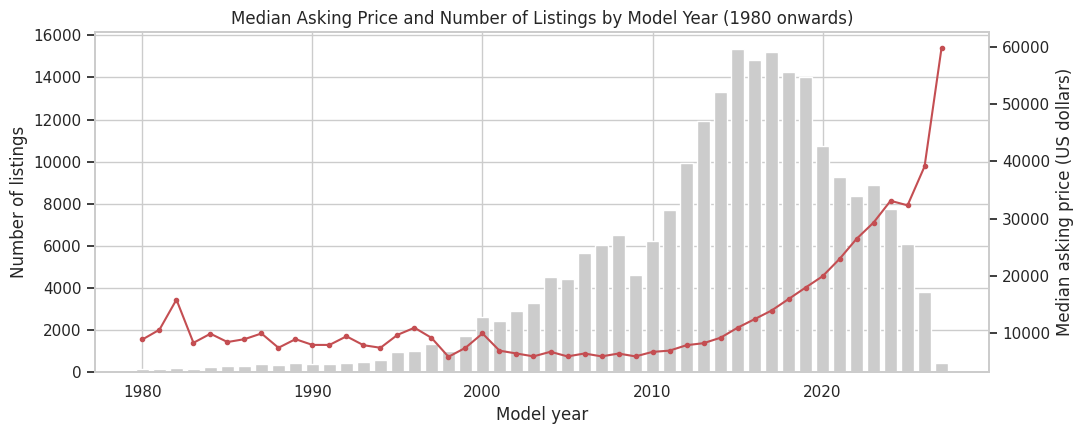

Median price peaks for model year 2027 ($59,831).
Average of the yearly medians for the newest 5 model years: $38,758  vs  oldest 11 years shown: $9,619.
Business reading: price rises steeply with newer model years, but very old vehicles can rise again (classic cars), so the relationship is not a straight line.


In [ ]:
# ---- 19.1 Price versus model year ----
year_view = df_eda[["year", "price"]].dropna()
year_view = year_view[year_view["year"] >= 1980].astype({"year": "int64"})
by_year = year_view.groupby("year")["price"].agg(median="median", listings="count")

fig, ax1 = plt.subplots(figsize=(11, 4.5))
ax1.bar(by_year.index, by_year["listings"], color="#CCCCCC", label="Number of listings")
ax1.set_xlabel("Model year")
ax1.set_ylabel("Number of listings")
ax2 = ax1.twinx()
ax2.plot(by_year.index, by_year["median"], color="#C44E52", marker="o", markersize=3, label="Median asking price")
ax2.set_ylabel("Median asking price (US dollars)")
ax1.set_title("Median Asking Price and Number of Listings by Model Year (1980 onwards)")
ax2.grid(False)
plt.tight_layout()
save_fig("02_price_by_year")
plt.show()

recent, older = by_year["median"].iloc[-5:].mean(), by_year["median"].loc[by_year.index <= by_year.index.min() + 10].mean()
peak_year = int(by_year["median"].idxmax())
print(f"Median price peaks for model year {peak_year} (${by_year['median'].max():,.0f}).")
print(f"Average of the yearly medians for the newest 5 model years: ${recent:,.0f}  vs  oldest 11 years shown: ${older:,.0f}.")
print("Business reading: price rises steeply with newer model years, but very old vehicles can rise again (classic cars), "
      "so the relationship is not a straight line.")

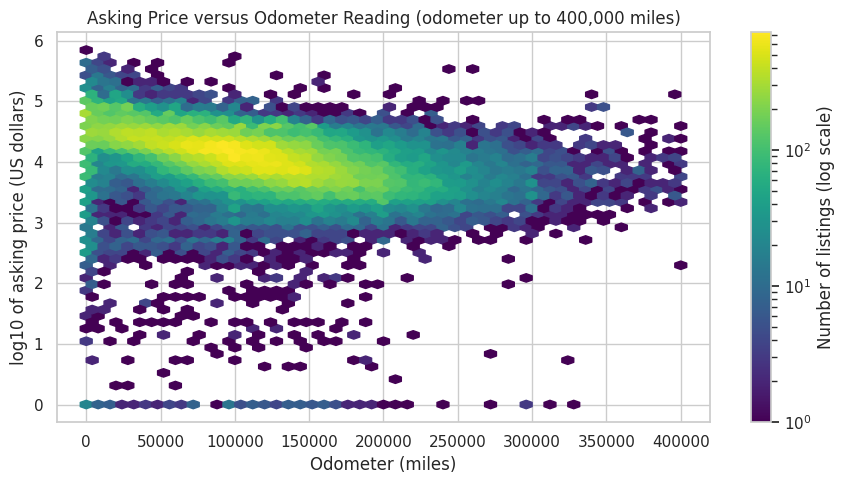

Spearman rank correlation between odometer and price: -0.55
Business reading: higher mileage goes with lower asking prices, but the spread is wide - mileage alone does not set the price.


In [ ]:
# ---- 19.2 Price versus mileage ----
odo_view = df_eda[["odometer", "price"]].dropna()
odo_view = odo_view[odo_view["odometer"] <= 400_000].astype(float)
odo_plot = odo_view.sample(n=min(80_000, len(odo_view)), random_state=42)

fig, ax = plt.subplots(figsize=(9, 5))
hb = ax.hexbin(odo_plot["odometer"], np.log10(odo_plot["price"]), gridsize=50, cmap="viridis", mincnt=1, bins="log")
fig.colorbar(hb, ax=ax, label="Number of listings (log scale)")
ax.set_title("Asking Price versus Odometer Reading (odometer up to 400,000 miles)")
ax.set_xlabel("Odometer (miles)")
ax.set_ylabel("log10 of asking price (US dollars)")
plt.tight_layout()
save_fig("03_price_vs_odometer")
plt.show()

rho = odo_view.corr(method="spearman").loc["odometer", "price"]
print(f"Spearman rank correlation between odometer and price: {rho:.2f}")
print("Business reading: higher mileage goes with lower asking prices, but the spread is wide - mileage alone does not set the price.")

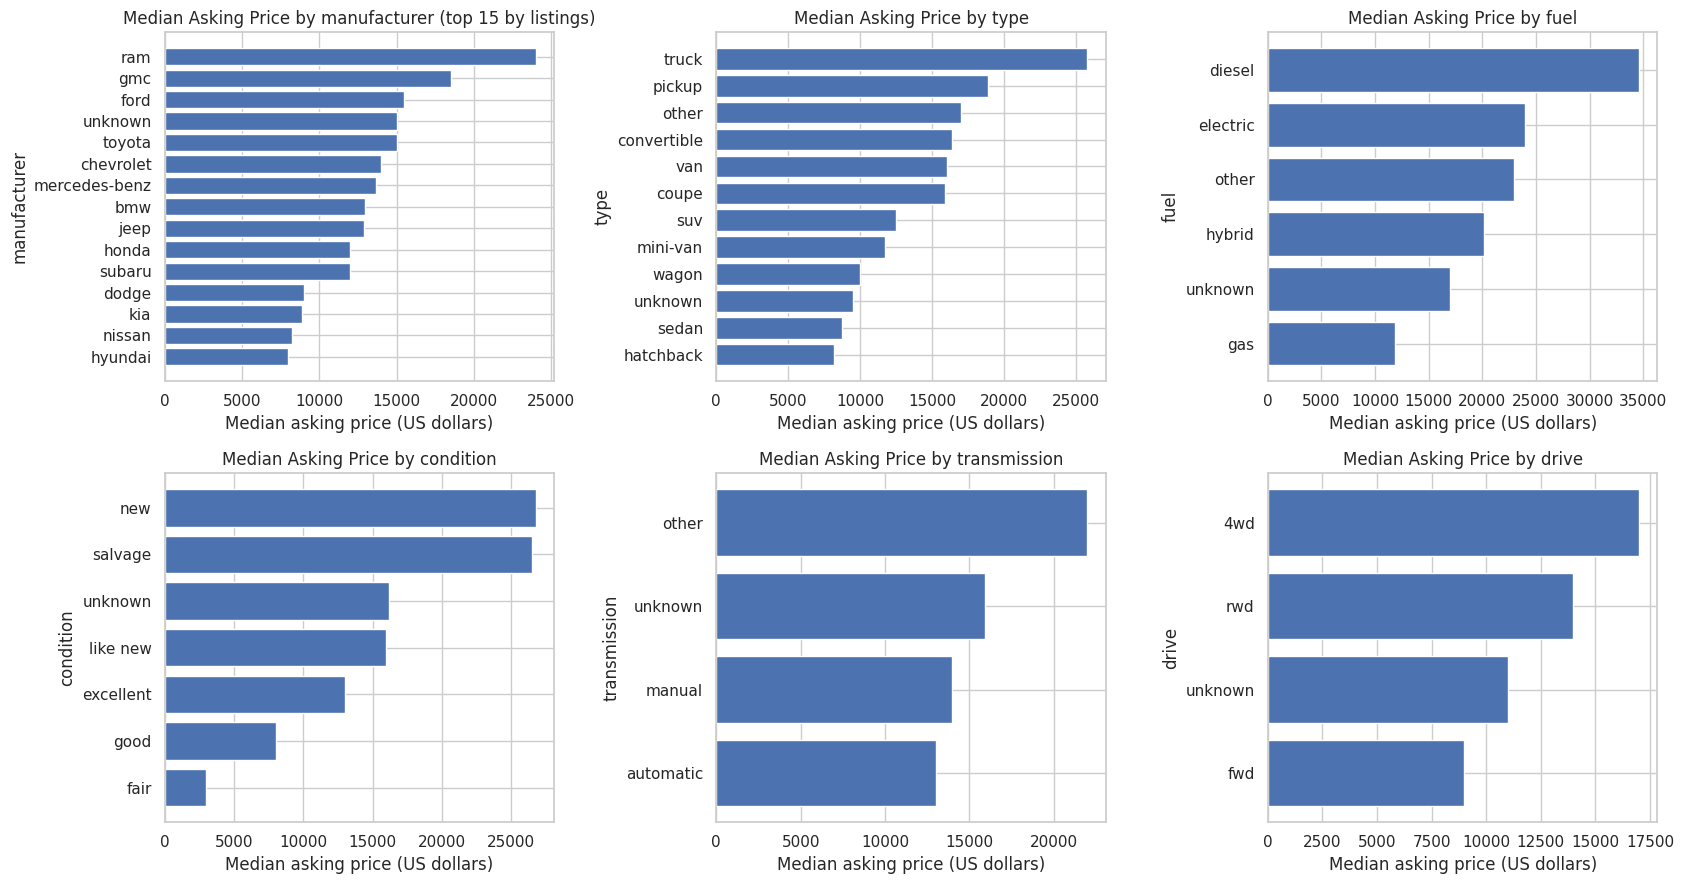

Fuel type: median price ranges from $11,900 (gas) to $34,600 (diesel).
Listings with an unknown condition have a median price of $16,192 vs $10,900 when the condition is stated - so the 'unknown' category itself carries information.


In [ ]:
# ---- 19.3 Price by category (median price per group) ----
def median_by(col, top=None):
    stats = df_eda.groupby(col)["price"].agg(median="median", listings="count")
    stats = stats[stats["listings"] >= MIN_GROUP].sort_values("listings", ascending=False)
    if top:
        stats = stats.head(top)
    return stats.sort_values("median")

panels = [("manufacturer", 15), ("type", None), ("fuel", None), ("condition", None), ("transmission", None), ("drive", None)]
panels = [(c, t) for c, t in panels if c in df_eda.columns]
fig, axes = plt.subplots(2, 3, figsize=(17, 9))
for ax, (col, top) in zip(axes.ravel(), panels):
    stats = median_by(col, top)
    ax.barh(stats.index.astype(str), stats["median"], color="#4C72B0")
    ax.set_title(f"Median Asking Price by {col}" + (f" (top {top} by listings)" if top else ""))
    ax.set_xlabel("Median asking price (US dollars)")
    ax.set_ylabel(col)
for ax in axes.ravel()[len(panels):]:
    ax.axis("off")
plt.tight_layout()
save_fig("04_price_by_category")
plt.show()

fuel_stats = median_by("fuel") if "fuel" in df_eda.columns else None
if fuel_stats is not None and len(fuel_stats) > 1:
    print(f"Fuel type: median price ranges from ${fuel_stats['median'].min():,.0f} ({fuel_stats['median'].idxmin()}) "
          f"to ${fuel_stats['median'].max():,.0f} ({fuel_stats['median'].idxmax()}).")
unk = df_eda.groupby(df_eda["condition"] == "unknown")["price"].median() if "condition" in df_eda.columns else None
if unk is not None and len(unk) == 2:
    print(f"Listings with an unknown condition have a median price of ${unk.loc[True]:,.0f} vs ${unk.loc[False]:,.0f} when the condition is stated "
          "- so the 'unknown' category itself carries information.")

,Variable,Kind,Strength
0,odometer,numeric (|Spearman rho|),0.551
1,year,numeric (|Spearman rho|),0.508
2,model,categorical (eta-squared),0.450
3,long,numeric (|Spearman rho|),0.186
4,condition,categorical (eta-squared),0.099
5,seller_type,categorical (eta-squared),0.095
6,type,categorical (eta-squared),0.080
7,fuel,categorical (eta-squared),0.070
8,manufacturer,categorical (eta-squared),0.063
9,region,categorical (eta-squared),0.060


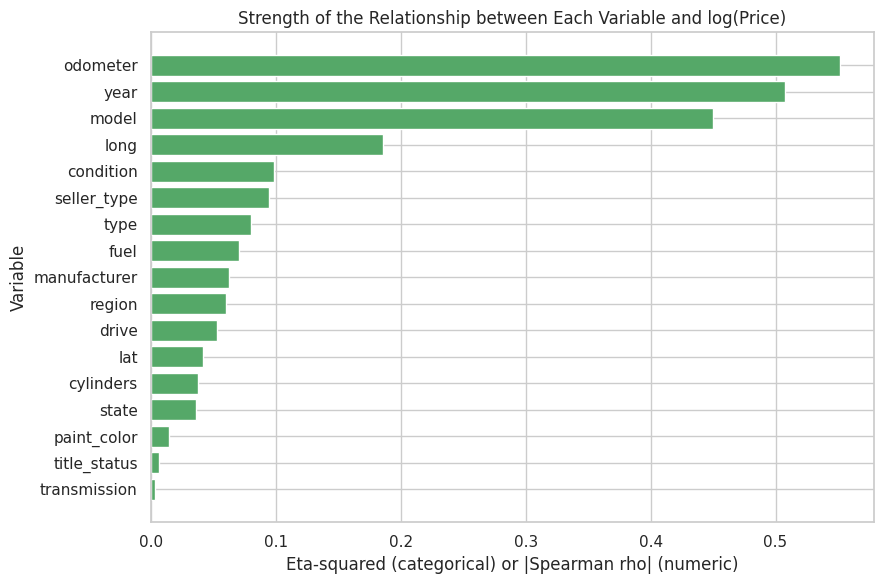

The three strongest single drivers of price in this dataset are: odometer, year, model.
Caution: eta-squared is inflated for variables with many categories (model, region), because many small groups fit noise.


In [ ]:
# ---- 19.4 Which variables explain the most price variation? ----
df_eda_log = df_eda.assign(log_price=np.log1p(df_eda["price"].astype(float)))

def correlation_ratio(frame, category, target="log_price"):
    """Eta-squared: share of the variation of the target that is explained by group membership (0 to 1)."""
    groups = frame.groupby(category)[target]
    counts, means = groups.count(), groups.mean()
    grand_mean = frame[target].mean()
    between = (counts * (means - grand_mean) ** 2).sum()
    total = ((frame[target] - grand_mean) ** 2).sum()
    return float(between / total) if total > 0 else np.nan

driver_rows = []
for col in ["manufacturer", "model", "type", "fuel", "condition", "cylinders", "transmission", "drive", "title_status",
            "size", "paint_color", "seller_type", "state", "region"]:
    if col in df_eda_log.columns:
        driver_rows.append({"Variable": col, "Kind": "categorical (eta-squared)", "Strength": correlation_ratio(df_eda_log, col)})
for col in ["year", "odometer", "lat", "long"]:
    if col in df_eda_log.columns:
        pair = df_eda_log[[col, "log_price"]].dropna().astype(float)
        driver_rows.append({"Variable": col, "Kind": "numeric (|Spearman rho|)", "Strength": abs(pair.corr(method="spearman").iloc[0, 1])})

driver_table = pd.DataFrame(driver_rows).sort_values("Strength", ascending=False).reset_index(drop=True)
display(driver_table.round(3))

fig, ax = plt.subplots(figsize=(9, 6))
plot_drivers = driver_table.sort_values("Strength")
ax.barh(plot_drivers["Variable"], plot_drivers["Strength"], color="#55A868")
ax.set_title("Strength of the Relationship between Each Variable and log(Price)")
ax.set_xlabel("Eta-squared (categorical) or |Spearman rho| (numeric)")
ax.set_ylabel("Variable")
plt.tight_layout()
save_fig("05_driver_strength")
plt.show()

top3 = driver_table["Variable"].head(3).tolist()
print(f"The three strongest single drivers of price in this dataset are: {', '.join(top3)}.")
print("Caution: eta-squared is inflated for variables with many categories (model, region), because many small groups fit noise.")

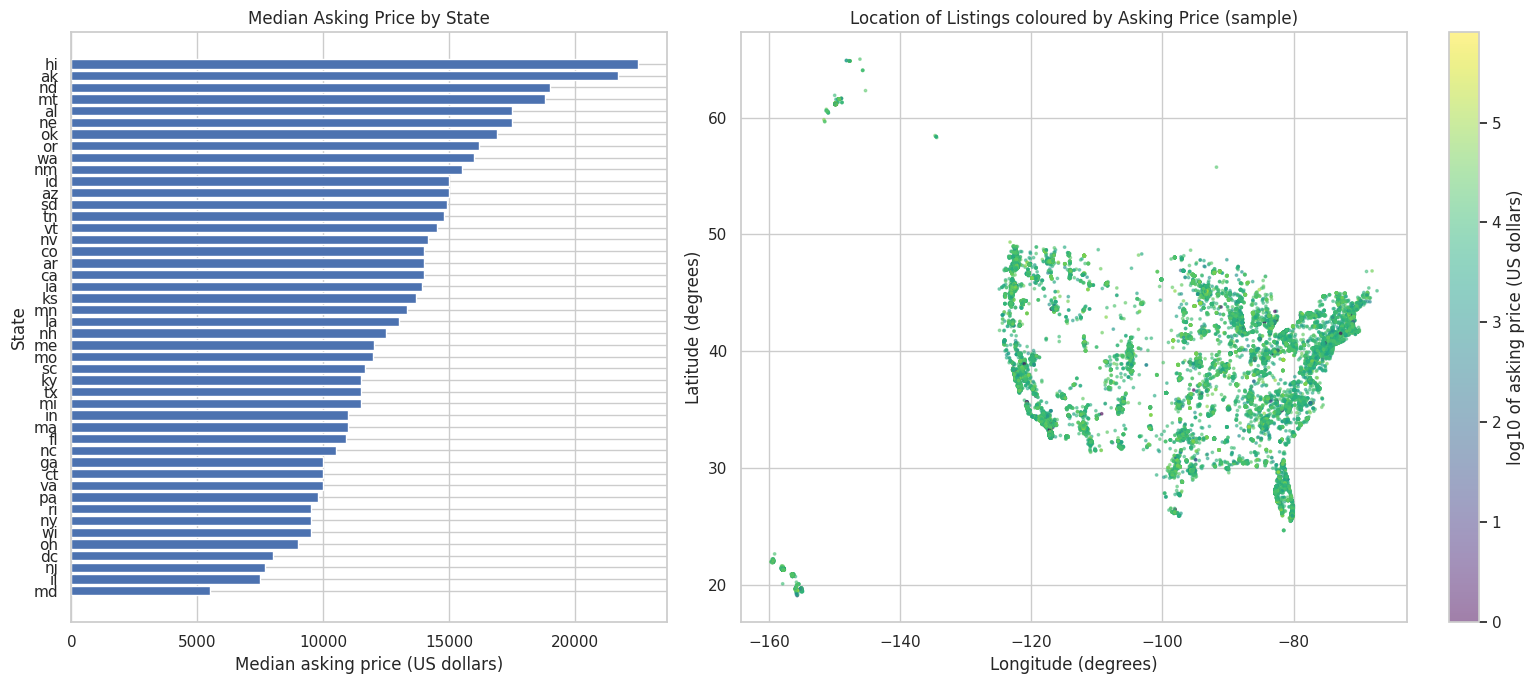

Median price is highest in 'hi' ($22,500) and lowest in 'md' ($5,500).
Business reading: location shifts prices (vehicle mix, demand, rural vs urban), so a regional feature is meaningful.


In [ ]:
# ---- 19.5 Geography ----
if "state" not in df_eda.columns:
    raise KeyError("Column 'state' not found - skip this geography cell or adapt it to your dataset version.")
state_stats = df_eda.groupby("state")["price"].agg(median="median", listings="count")
state_stats = state_stats[(state_stats["listings"] >= MIN_GROUP) & (state_stats.index != "unknown")].sort_values("median")

fig, axes = plt.subplots(1, 2, figsize=(16, 7), gridspec_kw={"width_ratios": [1, 1.4]})
axes[0].barh(state_stats.index, state_stats["median"], color="#4C72B0")
axes[0].set_title("Median Asking Price by State")
axes[0].set_xlabel("Median asking price (US dollars)")
axes[0].set_ylabel("State")
geo = eda_sample[["lat", "long", "price"]].dropna().astype(float) if {"lat", "long"} <= set(eda_sample.columns) else pd.DataFrame()
if len(geo):
    sc = axes[1].scatter(geo["long"], geo["lat"], c=np.log10(geo["price"]), s=3, cmap="viridis", alpha=0.5)
    fig.colorbar(sc, ax=axes[1], label="log10 of asking price (US dollars)")
axes[1].set_title("Location of Listings coloured by Asking Price (sample)")
axes[1].set_xlabel("Longitude (degrees)")
axes[1].set_ylabel("Latitude (degrees)")
plt.tight_layout()
save_fig("06_geography")
plt.show()

if len(state_stats) > 1:
    print(f"Median price is highest in '{state_stats['median'].idxmax()}' (${state_stats['median'].max():,.0f}) "
          f"and lowest in '{state_stats['median'].idxmin()}' (${state_stats['median'].min():,.0f}).")
print("Business reading: location shifts prices (vehicle mix, demand, rural vs urban), so a regional feature is meaningful.")

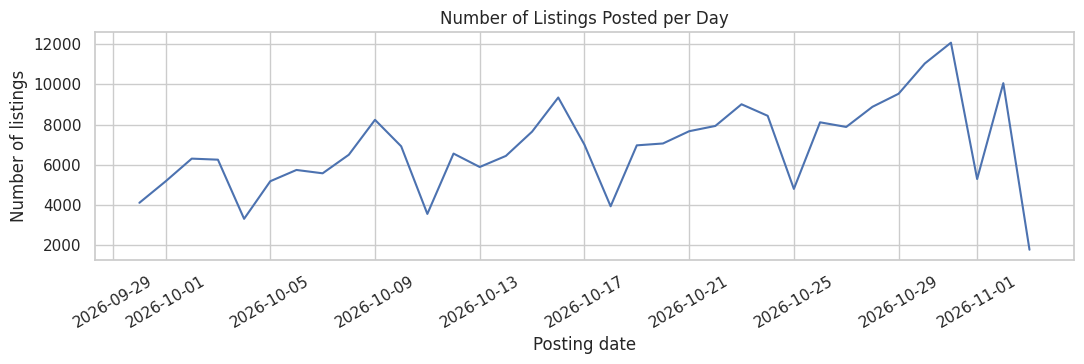

Listings were posted between 2026-09-30 and 2026-11-03 (35 days).
Business reading: the data is a short snapshot, so seasonal effects cannot be learned and prices may drift over time (a limitation).


In [ ]:
# ---- 19.6 Data-collection period ----
if "posting_date" in df_eda.columns and df_eda["posting_date"].notna().any():
    per_day = df_eda["posting_date"].dt.date.value_counts().sort_index()
    fig, ax = plt.subplots(figsize=(11, 3.8))
    ax.plot(pd.to_datetime(per_day.index), per_day.values, color="#4C72B0")
    ax.set_title("Number of Listings Posted per Day")
    ax.set_xlabel("Posting date")
    ax.set_ylabel("Number of listings")
    plt.xticks(rotation=30)
    plt.tight_layout()
    save_fig("07_listings_per_day")
    plt.show()
    print(f"Listings were posted between {per_day.index.min()} and {per_day.index.max()} ({len(per_day)} days).")
    print("Business reading: the data is a short snapshot, so seasonal effects cannot be learned and prices may drift over time (a limitation).")
else:
    print("posting_date not available - time analysis skipped.")

### Interpretation – Section 19 (summary of findings)
1. **Age** (model year) and **mileage** are the strongest numerical drivers; both relationships are curved, not straight.
2. **Brand, model and vehicle type** separate cheap and expensive segments; **fuel**, **drive** and **condition** add further differences.
3. A missing (`unknown`) condition is itself informative about price.
4. **Location** matters moderately.
5. The data covers a short time window, so the model will describe the market of that period.

These findings motivate the features created in Section 20.

## 20. Feature Engineering

**What will happen?** New columns are created from existing ones and stored in a small Python module (`src/vehicle_features.py`).
**Why a module?** The *same* code must run during training and inside the deployed app. Putting it in one file guarantees identical features (no training/serving mismatch).

| New feature | Definition | Business reasoning | Available when the app is used? |
|---|---|---|---|
| `vehicle_age` | reference year − model year (fixed constant = data-collection year) | Age is the main driver of depreciation | Yes |
| `miles_per_year` | odometer ÷ max(age, 1) | Separates normal from unusually heavy/light use | Yes |
| `cylinders_num` | number extracted from text such as "6 cylinders" | Turns text into an engine-size proxy | Yes |
| `is_luxury_brand` | manufacturer is in a fixed list of luxury brands | Luxury brands hold different price levels | Yes |
| `is_electrified` | fuel is electric or hybrid | Different price dynamics | Yes |
| `title_issue` | title status is salvage, rebuilt, lien, etc. | Branded titles sell for much less | Yes |
| `state_region` | US Census region of the state | Groups 50 states into 4 regions to reduce noise | Yes |

**Exploration-only features** (created below to test their value, but **not used in the deployed model** because they only exist after a seller has written the advert): `description_length`, `has_vin`, `posting_dayofweek`.

**No leakage:** none of these features uses `price` or any statistic learned from the data. Only fixed constants (reference year, brand list, region map) are used.

In [ ]:
FEATURES_MODULE = r"""
# vehicle_features.py - shared feature engineering for training (notebook) and deployment (Streamlit app).
import numpy as np
import pandas as pd

REFERENCE_YEAR = __REFERENCE_YEAR__      # data-collection year (fixed constant, NOT learned from prices)
PRICE_CAP = __PRICE_CAP__                # plausibility cap used in Stage 3

LUXURY_BRANDS = {"acura", "alfa-romeo", "aston-martin", "audi", "bentley", "bmw", "cadillac", "ferrari", "infiniti",
                 "jaguar", "land rover", "lexus", "lincoln", "maserati", "mercedes-benz", "porsche", "rolls-royce",
                 "tesla", "volvo"}

_REGIONS = {
    "northeast": "ct me ma nh ri vt nj ny pa",
    "midwest": "il in mi oh wi ia ks mn mo ne nd sd",
    "south": "de fl ga md nc sc va dc wv al ky ms tn ar la ok tx",
    "west": "az co id mt nv nm ut wy ak ca hi or wa",
}
STATE_REGION = {state: region for region, states in _REGIONS.items() for state in states.split()}

RAW_INPUT_COLUMNS = ["year", "odometer", "manufacturer", "model", "condition", "cylinders", "fuel",
                     "title_status", "transmission", "drive", "size", "type", "paint_color", "seller_type", "state"]
CATEGORICAL_RAW = ["manufacturer", "model", "condition", "cylinders", "fuel", "title_status",
                   "transmission", "drive", "size", "type", "paint_color", "seller_type", "state"]
NUMERIC_FEATURES = ["year", "odometer", "vehicle_age", "miles_per_year", "cylinders_num",
                    "is_luxury_brand", "is_electrified", "title_issue"]
CATEGORICAL_FEATURES = CATEGORICAL_RAW + ["state_region"]


def add_features(X):
    # Return a copy of X with cleaned categories and the engineered features added.
    X = X.copy()
    for col in ("year", "odometer"):
        if col not in X.columns:
            X[col] = np.nan
    year = pd.to_numeric(X["year"], errors="coerce").astype("float64")
    odometer = pd.to_numeric(X["odometer"], errors="coerce").astype("float64")
    X["year"], X["odometer"] = year, odometer

    for col in CATEGORICAL_RAW:
        if col not in X.columns:                 # column absent in this dataset version -> treated as unknown
            X[col] = np.nan
        values = X[col].astype("object")
        values = values.where(values.notna(), "unknown")
        X[col] = values.astype(str).str.strip().str.lower()

    age = (REFERENCE_YEAR - year).clip(lower=0)
    X["vehicle_age"] = age
    X["miles_per_year"] = odometer / age.clip(lower=1)
    X["cylinders_num"] = pd.to_numeric(X["cylinders"].str.extract(r"(\d+)")[0], errors="coerce")
    X["is_luxury_brand"] = X["manufacturer"].isin(LUXURY_BRANDS).astype(int)
    X["is_electrified"] = X["fuel"].isin(["electric", "hybrid"]).astype(int)
    X["title_issue"] = (~X["title_status"].isin(["clean", "unknown"])).astype(int)
    X["state_region"] = X["state"].map(STATE_REGION).fillna("unknown")
    return X


def inverse_log_price(values):
    # Convert log(1 + price) predictions back to dollars; clipping avoids absurd outputs for extreme inputs.
    return np.expm1(np.clip(values, 0.0, np.log1p(PRICE_CAP)))


def build_input_frame(values):
    # One-row DataFrame from a dictionary of user inputs.
    return pd.DataFrame([{c: values.get(c, np.nan) for c in RAW_INPUT_COLUMNS}])


def validate_inputs(values):
    # Return a list of problems with the user's inputs (empty list = valid).
    problems = []
    year, odometer = values.get("year"), values.get("odometer")
    if year is None or not (1950 <= year <= REFERENCE_YEAR + 1):
        problems.append(f"Model year must be between 1950 and {REFERENCE_YEAR + 1}.")
    if odometer is None or not (0 <= odometer <= 1_000_000):
        problems.append("Odometer must be between 0 and 1,000,000 miles.")
    if not str(values.get("manufacturer", "")).strip():
        problems.append("Please choose a manufacturer.")
    return problems


def predict_price(model, values, ratio_low=None, ratio_high=None):
    # Estimate the asking price (US dollars) and an optional range from empirical error ratios.
    estimate = float(model.predict(build_input_frame(values))[0])
    result = {"estimate": estimate}
    if ratio_low is not None and ratio_high is not None:
        result["low"], result["high"] = estimate * ratio_low, estimate * ratio_high
    return result
"""

SRC_DIR.mkdir(parents=True, exist_ok=True)
(SRC_DIR / "vehicle_features.py").write_text(FEATURES_MODULE.replace("__REFERENCE_YEAR__", str(DATA_COLLECTION_YEAR)).replace("__PRICE_CAP__", str(PRICE_MAX_PLAUSIBLE)), encoding="utf-8")

import importlib
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))
import vehicle_features as vf
importlib.reload(vf)
print(f"Feature module written to {SRC_DIR / 'vehicle_features.py'} (reference year = {vf.REFERENCE_YEAR})")

Feature module written to /content/drive/MyDrive/Used-Vehicle-Price-Prediction/src/vehicle_features.py (reference year = 2026)


In [ ]:
# Apply the feature engineering to the cleaned data (for exploration)
df_fe = vf.add_features(df_cleaned.reindex(columns=vf.RAW_INPUT_COLUMNS))
df_fe["price"] = df_cleaned["price"].astype(float)
df_fe["log_price"] = np.log1p(df_fe["price"])

# Exploration-only features (not available when a user asks the app for a price)
description_text = df_cleaned["description"] if "description" in df_cleaned.columns else pd.Series(np.nan, index=df_cleaned.index)
df_fe["description_length"] = description_text.astype("object").str.len()
df_fe["has_vin"] = (df_cleaned["vin"].notna().astype(int) if "vin" in df_cleaned.columns else 0)
df_fe["posting_dayofweek"] = df_cleaned["posting_date"].dt.dayofweek if "posting_date" in df_cleaned.columns else np.nan

engineered = ["vehicle_age", "miles_per_year", "cylinders_num", "is_luxury_brand", "is_electrified", "title_issue"]
print("First rows of the engineered features:")
display(df_fe[["year", "odometer"] + engineered + ["state_region", "price"]].head())

print("\nMissing values in the engineered features (these remain NaN and are handled inside the model pipeline):")
display(df_fe[engineered].isna().sum().to_frame("missing").assign(**{"% missing": lambda d: (d["missing"] / len(df_fe) * 100).round(2)}))

First rows of the engineered features:


,year,odometer,vehicle_age,miles_per_year,cylinders_num,is_luxury_brand,is_electrified,title_issue,state_region,price
0,2022.0,99179.0,4.0,24794.750000,6.0,0,0,0,west,27999.0
1,1969.0,90000.0,57.0,1578.947368,4.0,0,0,0,west,2200.0
2,2016.0,82896.0,10.0,8289.600000,6.0,0,0,0,west,15999.0
3,1974.0,89687.0,52.0,1724.750000,8.0,1,0,0,west,12000.0
4,2009.0,81724.0,17.0,4807.294118,8.0,0,0,0,west,18999.0



Missing values in the engineered features (these remain NaN and are handled inside the model pipeline):


,missing,% missing
vehicle_age,13,0.01
miles_per_year,3723,1.55
cylinders_num,72832,30.32
is_luxury_brand,0,0.00
is_electrified,0,0.00
title_issue,0,0.00


## 21. Testing the Value of the Features

**What will happen?** We check how strongly each new feature is related to price, show the correlations in a heatmap and compare group medians for the yes/no features.
**Why?** Features should be *tested for value*, not just created. A later experiment in Stage 5 additionally measures whether the engineered features improve the model.

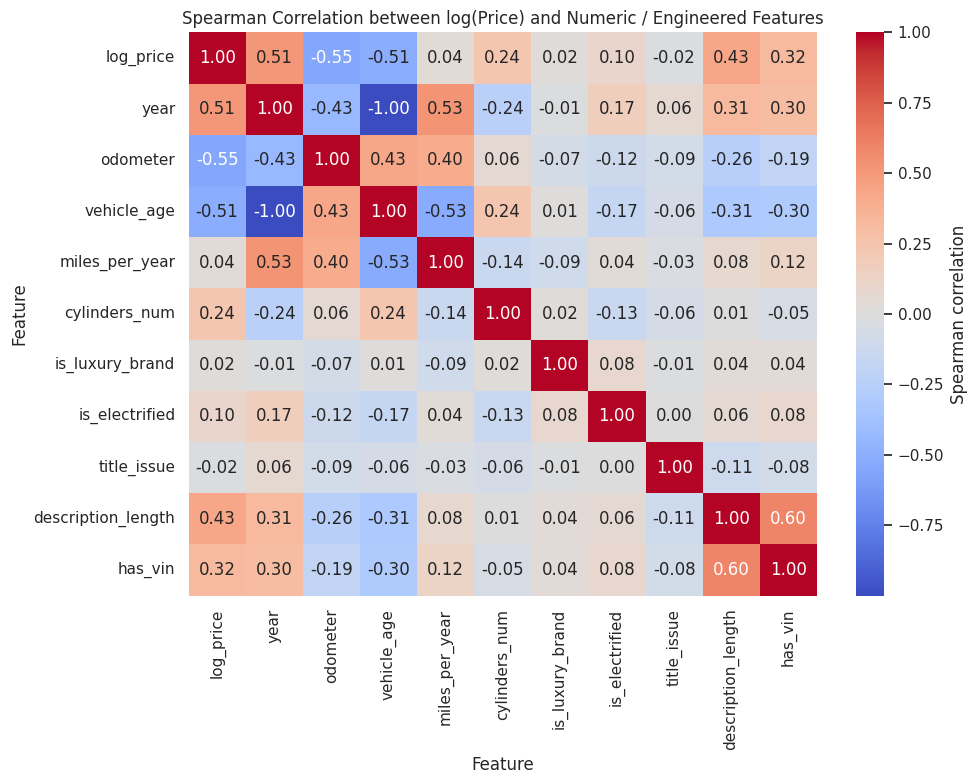

,spearman_with_log_price
odometer,-0.551
vehicle_age,-0.508
year,0.508
description_length,0.434
has_vin,0.318
cylinders_num,0.237
is_electrified,0.101
miles_per_year,0.041
title_issue,-0.022
is_luxury_brand,0.019


In [ ]:
numeric_for_corr = ["log_price", "year", "odometer", "vehicle_age", "miles_per_year", "cylinders_num",
                    "is_luxury_brand", "is_electrified", "title_issue", "description_length", "has_vin"]
corr = df_fe[numeric_for_corr].astype(float).corr(method="spearman")

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax, cbar_kws={"label": "Spearman correlation"})
ax.set_title("Spearman Correlation between log(Price) and Numeric / Engineered Features")
ax.set_xlabel("Feature")
ax.set_ylabel("Feature")
plt.tight_layout()
save_fig("08_feature_correlation")
plt.show()

feature_value = corr["log_price"].drop("log_price").to_frame("spearman_with_log_price")
feature_value["abs"] = feature_value["spearman_with_log_price"].abs()
display(feature_value.sort_values("abs", ascending=False).drop(columns="abs").round(3))

,Feature,Median price if No,Median price if Yes,Listings (No),Listings (Yes),Ratio Yes/No
0,Luxury brand,12999.0,13000.0,201074,39112,1.00
1,Electric / hybrid,12994.0,21999.0,230528,9658,1.69
2,"Title issue (salvage, rebuilt, ...)",13000.0,12784.0,227846,12340,0.98
3,Advert shows a VIN,8595.0,16599.0,99676,140510,1.93


,median,listings
state_region,,
midwest,10995.0,32702
northeast,9995.0,28294
south,11000.0,49273
west,15000.0,129917


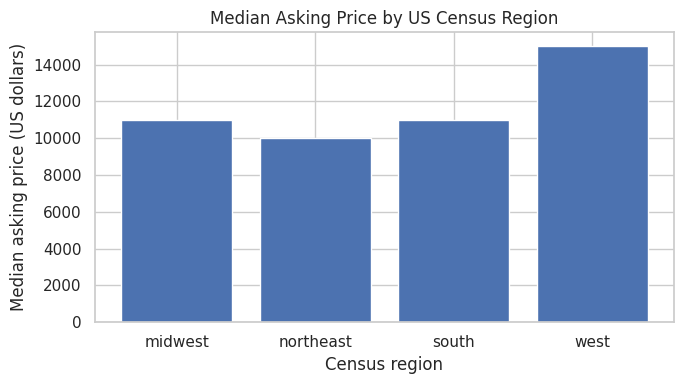

In [ ]:
group_rows = []
for flag, label in [("is_luxury_brand", "Luxury brand"), ("is_electrified", "Electric / hybrid"), ("title_issue", "Title issue (salvage, rebuilt, ...)"),
                    ("has_vin", "Advert shows a VIN")]:
    medians = df_fe.groupby(flag)["price"].median()
    counts = df_fe.groupby(flag)["price"].count()
    if {0, 1} <= set(medians.index):
        group_rows.append({"Feature": label, "Median price if No": medians[0], "Median price if Yes": medians[1],
                           "Listings (No)": counts[0], "Listings (Yes)": counts[1],
                           "Ratio Yes/No": round(medians[1] / medians[0], 2)})
group_table = pd.DataFrame(group_rows)
display(group_table)

region_medians = df_fe[df_fe["state_region"] != "unknown"].groupby("state_region")["price"].agg(median="median", listings="count")
display(region_medians)

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(region_medians.index, region_medians["median"], color="#4C72B0")
ax.set_title("Median Asking Price by US Census Region")
ax.set_xlabel("Census region")
ax.set_ylabel("Median asking price (US dollars)")
plt.tight_layout()
save_fig("09_price_by_region")
plt.show()

In [ ]:
# Documentation table of the engineered features (exported for the repository)
feature_engineering_table = pd.DataFrame([
    ["vehicle_age", "REFERENCE_YEAR - year (clipped at 0)", "Age drives depreciation", "Yes", "Used in model"],
    ["miles_per_year", "odometer / max(vehicle_age, 1)", "Usage intensity", "Yes", "Used in model"],
    ["cylinders_num", "number extracted from the cylinders text", "Engine-size proxy", "Yes", "Used in model"],
    ["is_luxury_brand", "manufacturer in fixed luxury list", "Brand tier", "Yes", "Used in model"],
    ["is_electrified", "fuel is electric or hybrid", "Powertrain type", "Yes", "Used in model"],
    ["title_issue", "title status not clean/unknown", "Branded titles lose value", "Yes", "Used in model"],
    ["state_region", "Census region of the state", "Reduces 50 states to 4 regions", "Yes", "Used in model"],
    ["description_length", "characters in the advert text", "Effort/detail of the seller", "No", "Exploration only"],
    ["has_vin", "VIN present", "Seller transparency", "No", "Exploration only"],
    ["posting_dayofweek", "weekday of the posting", "Timing effects", "No", "Exploration only"],
], columns=["Feature", "Definition", "Business reasoning", "Available at prediction time", "Status"])
display(feature_engineering_table)
feature_engineering_table.to_csv(OUTPUT_DIR / "feature_engineering_table.csv", index=False)
driver_table.to_csv(OUTPUT_DIR / "eda_driver_strength.csv", index=False)
print("Saved feature table and driver table to outputs/.")

,Feature,Definition,Business reasoning,Available at prediction time,Status
0,vehicle_age,REFERENCE_YEAR - year (clipped at 0),Age drives depreciation,Yes,Used in model
1,miles_per_year,"odometer / max(vehicle_age, 1)",Usage intensity,Yes,Used in model
2,cylinders_num,number extracted from the cylinders text,Engine-size proxy,Yes,Used in model
3,is_luxury_brand,manufacturer in fixed luxury list,Brand tier,Yes,Used in model
4,is_electrified,fuel is electric or hybrid,Powertrain type,Yes,Used in model
5,title_issue,title status not clean/unknown,Branded titles lose value,Yes,Used in model
6,state_region,Census region of the state,Reduces 50 states to 4 regions,Yes,Used in model
7,description_length,characters in the advert text,Effort/detail of the seller,No,Exploration only
8,has_vin,VIN present,Seller transparency,No,Exploration only
9,posting_dayofweek,weekday of the posting,Timing effects,No,Exploration only


Saved feature table and driver table to outputs/.


### Interpretation – Stage 4 summary
- The heatmap and group medians show which engineered features carry information about price (look for large absolute correlations and large Yes/No price ratios).
- Features that exist only after the advert is written (`description_length`, `has_vin`, `posting_dayofweek`) are **excluded from the deployed model** because a user cannot supply them when asking for a price estimate. Using them would make the app impossible to use.
- All modelling features are leakage-free: they use only the listing's own attributes and fixed constants.
- **Stage 5** now tests whether the engineered features really improve prediction.

---
## Next step
Notebook 02 is finished. The EDA figures, feature table and `src/vehicle_features.py` are saved in your Drive folder.

**Open notebook `03_stages_5_6_modelling_tuning_evaluation.ipynb` next.**